<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   gender           7043 non-null   str  
 1   SeniorCitizen    7043 non-null   int64
 2   Dependents       7043 non-null   str  
 3   tenure           7043 non-null   int64
 4   PhoneService     7043 non-null   str  
 5   MultipleLines    7043 non-null   str  
 6   InternetService  7043 non-null   str  
 7   Contract         7043 non-null   str  
 8   MonthlyCharges   7043 non-null   int64
 9   Churn            7043 non-null   str  
dtypes: int64(3), str(7)
memory usage: 357.7 KB
Duplicate rows removed: 302
--- Unique values in gender ---
<StringArray>
['Female', 'Male']
Length: 2, dtype: str

--- Unique values in Dependents ---
<StringArray>
['No', 'Yes']
Length: 2, dtype: str

--- Unique values in PhoneService ---
<StringArray>
['No', 'Yes']
Length: 2, dtype: str

--- Unique values in MultipleLines -

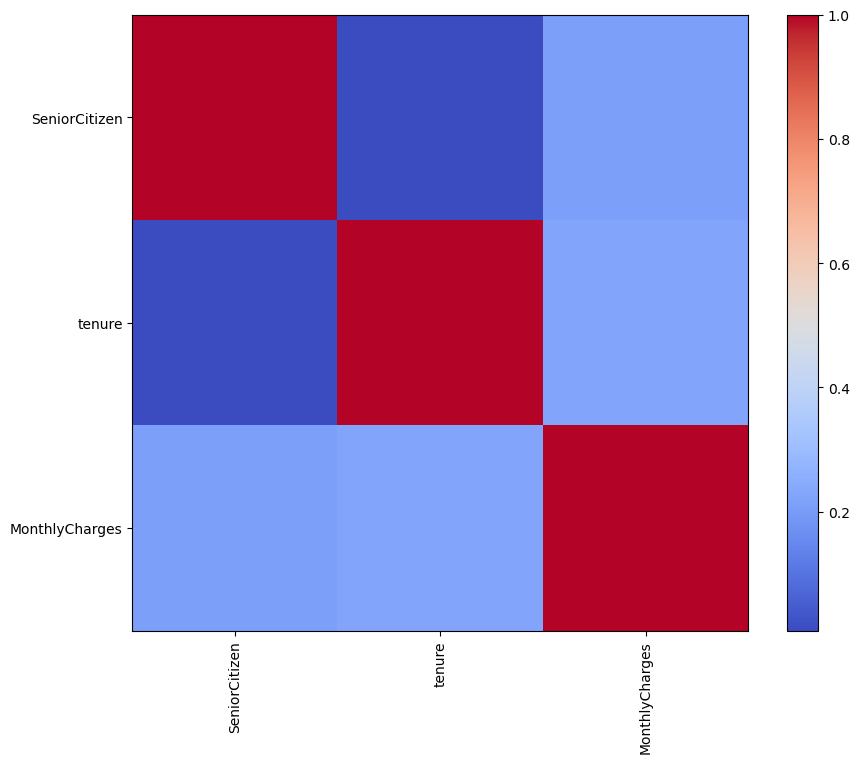

Final quality check:

Missing values:
gender                         0
SeniorCitizen                  0
Dependents                     0
tenure                         0
MonthlyCharges                 0
Churn                          0
PhoneService_Yes               0
MultipleLines_Yes              0
InternetService_Fiber optic    0
Contract_One year              0
Contract_Two year              0
dtype: int64

Duplicates:
0

Data types:
gender                             str
SeniorCitizen                  float64
Dependents                         str
tenure                         float64
MonthlyCharges                 float64
Churn                            int64
PhoneService_Yes                  bool
MultipleLines_Yes                 bool
InternetService_Fiber optic       bool
Contract_One year                 bool
Contract_Two year                 bool
dtype: object

Churn distribution:
Churn
0    4950
1    1791
Name: count, dtype: int64


In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

df = pd.read_csv("Dataset_ATS_v2.csv")

df.head()

df.shape

df.columns

df.info()

df.describe()

df.isnull().sum()

df.duplicated().sum()

before = len(df)

df = df.drop_duplicates()

removed = before - len(df)

print(f"Duplicate rows removed: {removed}")

df["Contract"].unique()

for col in df.select_dtypes(include=["object","string"]).columns:
    df[col] = df[col].str.strip()

columns_to_check = ["gender", "Dependents", "PhoneService", "MultipleLines", "InternetService", "Churn"]

for col in columns_to_check:
    print(f"--- Unique values in {col} ---")
    print(df[col].unique())
    print()

df["SeniorCitizen"] = pd.to_numeric(
    df["SeniorCitizen"],
    errors = 'coerce'
)

df["tenure"] = pd.to_numeric(
    df["tenure"],
    errors = 'coerce'
)

df["MonthlyCharges"] = pd.to_numeric(
    df["MonthlyCharges"],
    errors = 'coerce'
)

df["MonthlyCharges"].describe()

(df["MonthlyCharges"] < 0).sum()

(df["tenure"] <0).sum()

df["tenure"].max()

df["Churn"].value_counts()

df["Churn"].value_counts(normalize=True) * 100

Q1 = df["MonthlyCharges"].quantile(0.25)
Q3 = df["MonthlyCharges"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[
    (df["MonthlyCharges"] < lower) |
    (df["MonthlyCharges"] > upper)
]

print(outliers.shape)

numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(10, 8))
plt.imshow(numeric_df.corr(), cmap="coolwarm")
plt.colorbar()
plt.xticks(range(len(numeric_df.columns)),
           numeric_df.columns,
           rotation=90)
plt.yticks(range(len(numeric_df.columns)),
           numeric_df.columns)
plt.show()

df = pd.get_dummies(
    df,
    columns = ["PhoneService", "MultipleLines", "InternetService", "Contract"],
    drop_first = True
)

scaler = StandardScaler()

numerical_columns = [
    "SeniorCitizen",
    "tenure",
    "MonthlyCharges"
]

df[numerical_columns] = scaler.fit_transform(
    df[numerical_columns]
)

df["Churn"] = df["Churn"].map({
    "No" : 0,
    "Yes" : 1
})

x = df.drop("Churn", axis = 1)
y = df["Churn"]

x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size = 0.2,
    random_state = 42,
    stratify = y
)

x_train.loc[:, numerical_columns] = scaler.fit_transform(
    x_train[numerical_columns]
)

x_test.loc[:, numerical_columns] = scaler.transform(
    x_test[numerical_columns]
)

x_train.to_csv("X_train.csv", index = False)
x_test.to_csv("X_test.csv", index = False)
y_train.to_frame(name = "Churn").to_csv("Y_train.csv", index = False)
y_test.to_frame(name = "Churn").to_csv("Y_test.csv", index = False)

split_summary = pd.DataFrame({
    "Dataset" : ["Training", "Testing"],
    "Rows" : [len(x_train), len(x_test)],
    "Features" : [x_train.shape[1], x_test.shape[1]],
    "Churn_Yes" : [
        int((y_train == 1).sum()),
        int((y_test == 1).sum())
    ],
    "Churn_No" : [
        int((y_train == 0).sum()),
        int((y_test == 0).sum())
    ]
})

split_summary.to_csv("Tran_Test_Summary.csv", index = False)

print("Final quality check:")

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicates:")
print(df.duplicated().sum())

print("\nData types:")
print(df.dtypes)

print("\nChurn distribution:")
print(df["Churn"].value_counts())

df.to_csv('Updated_Dataset.csv', index = False)